# Étape 5 : DrBERT avec découpage en chunks et fenêtres de contexte

Première approche Deep Learning. On utilise DrBERT (`Dr-BERT/DrBERT-7GB`), un modèle pré-entraîné sur des textes médicaux en français. Il est limité à 512 tokens, alors qu'une bonne partie des comptes rendus est plus longue. Les textes sont donc préparés de la façon suivante :

| Document | Traitement |
|---|---|
| ≤ 510 tokens | gardé en entier |
| > 510 tokens avec une mention tabac (regex) | fenêtres de 50 tokens de chaque côté des mentions, mises bout à bout |
| > 510 tokens sans mention | découpé en morceaux de 510 tokens |

Un document peut donc donner plusieurs séquences, on regroupe ensuite leurs prédictions pour avoir une seule prédiction par document. Le split train/test est le même que dans `04_ML.ipynb` pour pouvoir comparer les résultats.

Notebook exécuté sur Google Colab (GPU T4).

## Installation et configuration

In [1]:
%pip install -q "transformers>=4.48" "accelerate>=0.34" sentencepiece protobuf pyarrow

In [2]:
import gc, json, os, re, sys, time, warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

import transformers
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup, set_seed
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report, cohen_kappa_score,
                             confusion_matrix, f1_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore", category=FutureWarning)
transformers.logging.set_verbosity_error()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| transformers", transformers.__version__, "| device :", DEVICE)
if DEVICE == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("Pas de GPU")

# calcul en fp16 sur GPU pour aller plus vite et prendre moins de mémoire
USE_AMP = DEVICE == "cuda"

torch 2.14.1+cu130 | transformers 5.22.1 | device : cuda
Tesla T4


In [4]:
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/stage_m2"
else:
    BASE_DIR = "."

# preproc.py et rules.py sont à la racine du projet (en local et sur le Drive)
sys.path.append(BASE_DIR)
from preproc import PARHAFPreprocessor
from rules import evaluer_algorithme
prep = PARHAFPreprocessor()

DATA_DIR = os.path.join(BASE_DIR, "data")
CSV_PATH = os.path.join(DATA_DIR, "annotated_corrected.csv")
PARQUET_PATH = os.path.join(DATA_DIR, "train-00000-of-00001.parquet")
RUN_NAME = "drbert_chunking"
OUT_DIR = os.path.join(BASE_DIR, "results", RUN_NAME)
os.makedirs(OUT_DIR, exist_ok=True)

SEED, TEST_SIZE, VAL_SIZE = 42, 0.2, 0.15   # même split que 04_ML

MODEL_CHECKPOINT = "Dr-BERT/DrBERT-7GB"
MAX_LEN = 512
CTX_TOKENS = 50   # tokens gardés de chaque côté d'une mention

EPOCHS, LR, WEIGHT_DECAY, WARMUP_RATIO = 8, 2e-5, 0.01, 0.1
TRAIN_BS, GRAD_ACC, EVAL_BS = 8, 2, 32

RE_TABAC = re.compile(prep.re_tabac, flags=re.IGNORECASE)   # regex de preproc.py

set_seed(SEED)
assert os.path.exists(CSV_PATH), CSV_PATH

Mounted at /content/drive


## 5.1 Données et split train / test

On reprend exactement le split de `04_ML.ipynb` (même `LabelEncoder`, `test_size=0.2`, `random_state=42`, stratifié), ce qui donne 477 documents en train et 120 en test. Le split est fait sur les documents, avant tout découpage, donc un même document ne peut pas se retrouver dans le train et dans le test.

Le texte de `annotated_corrected.csv` n'a plus de ponctuation, ce qui est gênant pour un transformer (négations, abréviations...). On récupère donc le texte brut dans le parquet PARHAF avec `explode_cols` de `preproc.py`, et on vérifie avec `clean_text` qu'il redonne bien le texte du CSV.

15 % du train est mis de côté comme validation pour choisir la meilleure epoch.

In [5]:
df = pd.read_csv(CSV_PATH)[["id", "text", "label"]].copy()
df["label"] = df["label"].astype(str).str.strip()

le = LabelEncoder()
df["label_id"] = le.fit_transform(df["label"])
CLASSES = list(le.classes_)
NUM_LABELS = len(CLASSES)
ID2LABEL = dict(enumerate(CLASSES))
LABEL2ID = {c: i for i, c in ID2LABEL.items()}

# même split que 04_ML
idx_train, idx_test = train_test_split(df.index.values, test_size=TEST_SIZE, random_state=SEED,
                                       stratify=df["label_id"])

# texte brut du parquet, avec les mêmes id que le CSV (créés par explode_cols de preproc.py)
raw = prep.explode_cols(pd.read_parquet(PARQUET_PATH))
raw_text = df["id"].astype(str).map(dict(zip(raw["id"].astype(str), raw["text"])))
assert raw_text.notna().all(), "certains id du CSV ne sont pas dans le parquet"

# vérification : nettoyé avec clean_text, le texte brut doit redonner le texte du CSV
cleaned = prep.clean_text(pd.DataFrame({"text": raw_text}))["text"]
print(f"{(cleaned == df['text']).sum()}/{len(df)} textes identiques au CSV après nettoyage")
df["text"] = raw_text
del raw

df_train_full = df.loc[idx_train].copy()
df_test = df.loc[idx_test].copy()
df_train, df_val = train_test_split(df_train_full, test_size=VAL_SIZE, random_state=SEED,
                                    stratify=df_train_full["label_id"])

print(f"Train : {len(df_train)} | Validation : {len(df_val)} | Test : {len(df_test)}")
display(pd.DataFrame({s: d["label"].value_counts() for s, d in
                      [("train", df_train), ("val", df_val), ("test", df_test)]}).loc[CLASSES])

587/597 textes identiques au CSV après nettoyage
Train : 405 | Validation : 72 | Test : 120


,train,val,test
label,,,
Ancien fumeur,52,10,16
Fumeur actuel,63,11,18
Non mentionné,204,36,61
Non-fumeur,86,15,25


## 5.2 Fonctions utilitaires

Ces fonctions sont les mêmes dans les notebooks 05, 06 et 07 :
- `make_batch` et `predict_probs` : padding des séquences et prédiction, **dans l'ordre des séquences** ;
- `doc_probs` : regroupement des séquences d'un même document (moyenne des probabilités) ;
- `train_model` : la boucle d'entraînement, avec une cross-entropy pondérée par classe à cause du déséquilibre des labels. À la fin de chaque epoch on calcule le F1 macro de la validation par document, et on garde les poids de la meilleure epoch ;
- `evaluate_and_save` : l'évaluation sur le test (affichage avec `evaluer_algorithme` de `rules.py`), qui sauvegarde les prédictions et un `metrics.json` pour le notebook 08.

On n'utilise plus le `Trainer` de HuggingFace : avec l'option `group_by_length`, il changeait l'ordre des documents de validation, et les prédictions étaient comparées aux labels d'autres documents. Le F1 de validation était donc faux et la meilleure epoch choisie au hasard. Avec une boucle écrite à la main, on voit exactement ce qui se passe.

In [6]:
def make_batch(records, pad_to=None):
    # complète les séquences avec du padding pour qu'elles aient la même longueur
    batch = tokenizer.pad({"input_ids": [r["input_ids"] for r in records]}, return_tensors="pt",
                          padding="max_length" if pad_to else "longest", max_length=pad_to)
    batch["labels"] = torch.tensor([r["label_id"] for r in records])
    return batch


@torch.no_grad()
def predict_probs(model, records, batch_size, pad_to=None):
    # probabilités de chaque séquence, dans le même ordre que records
    model.eval()
    probs = []
    for i in range(0, len(records), batch_size):
        batch = make_batch(records[i:i + batch_size], pad_to)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(input_ids=batch["input_ids"].to(DEVICE),
                           attention_mask=batch["attention_mask"].to(DEVICE)).logits
        probs.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(probs)


def doc_probs(records, probs):
    # un document peut donner plusieurs séquences : on fait la moyenne de leurs probabilités
    doc_ids = [r["doc_id"] for r in records]
    return pd.DataFrame(probs, columns=CLASSES).groupby(doc_ids, sort=False).mean()


def scores(y_true, y_pred):
    return {"f1_macro": f1_score(y_true, y_pred, average="macro"),
            "accuracy": accuracy_score(y_true, y_pred),
            "kappa": cohen_kappa_score(y_true, y_pred)}


def get_class_weights(label_ids):
    # poids "balanced" : une classe rare compte plus dans la loss
    counts = np.bincount(label_ids, minlength=NUM_LABELS)
    weights = len(label_ids) / (NUM_LABELS * np.maximum(counts, 1))
    print("Poids des classes :", {c: round(float(w), 3) for c, w in zip(CLASSES, weights)})
    return torch.tensor(weights, dtype=torch.float32)


def train_model(model, train_records, val_score):
    # val_score(model) renvoie le F1 macro, l'accuracy et le kappa de la validation, par document
    loader = DataLoader(train_records, batch_size=TRAIN_BS, shuffle=True, collate_fn=make_batch)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    n_updates = EPOCHS * int(np.ceil(len(loader) / GRAD_ACC))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * n_updates), n_updates)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    class_weights = get_class_weights([r["label_id"] for r in train_records]).to(DEVICE)

    history, best_f1, best_weights = [], -1, None
    for epoch in range(1, EPOCHS + 1):
        model.train()
        total_loss = 0
        for step, batch in enumerate(loader, start=1):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
            loss = F.cross_entropy(logits.float(), batch["labels"], weight=class_weights)
            scaler.scale(loss / GRAD_ACC).backward()
            total_loss += loss.item()

            # on met à jour les poids tous les GRAD_ACC batchs (accumulation de gradient)
            if step % GRAD_ACC == 0 or step == len(loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                scheduler.step()
                optimizer.zero_grad()

        val = val_score(model)
        history.append({"epoch": epoch, "loss_train": total_loss / len(loader), **val})
        print(f"epoch {epoch:2d} | loss train {history[-1]['loss_train']:.4f} | "
              f"F1 val {val['f1_macro']:.4f} | accuracy val {val['accuracy']:.4f} | kappa val {val['kappa']:.4f}")

        # on garde une copie des poids de la meilleure epoch
        if val["f1_macro"] > best_f1:
            best_f1 = val["f1_macro"]
            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_weights)
    return pd.DataFrame(history), best_f1


def evaluate_and_save(name, doc_ids, y_true, y_pred, probs, extra_cols=None, infos=None):
    # affiche les résultats du test et les sauvegarde pour le notebook 08
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    labels = np.arange(NUM_LABELS)
    evaluer_algorithme([ID2LABEL[i] for i in y_true], [ID2LABEL[i] for i in y_pred], name, CLASSES)

    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    acc = accuracy_score(y_true, y_pred)
    kappa = cohen_kappa_score(y_true, y_pred)
    print(f"F1 macro : {f1:.4f} | Accuracy : {acc:.4f} | Précision : {prec:.4f} | Rappel : {rec:.4f}")

    pred_df = pd.DataFrame({"doc_id": list(doc_ids),
                            "y_true": [ID2LABEL[i] for i in y_true], "y_pred": [ID2LABEL[i] for i in y_pred],
                            "y_true_id": y_true, "y_pred_id": y_pred})
    for j, c in enumerate(CLASSES):
        pred_df[f"proba_{c}"] = np.asarray(probs)[:, j]
    for col, values in (extra_cols or {}).items():
        pred_df[col] = list(values)
    pred_df.to_csv(os.path.join(OUT_DIR, "predictions_test.csv"), index=False)

    report = classification_report(y_true, y_pred, labels=labels, target_names=CLASSES, output_dict=True, zero_division=0)
    metrics = {
        "Modèle": name, "run_name": RUN_NAME, "timestamp": datetime.now().isoformat(timespec="seconds"),
        "n_test_docs": len(y_true), "classes": CLASSES,
        "Accuracy": round(acc, 4), "Precision (macro)": round(prec, 4), "Recall (macro)": round(rec, 4),
        "F1-score (macro)": round(f1, 4), "kappa": round(kappa, 4),
        "per_class": {c: {k: round(v, 4) for k, v in report[c].items()} for c in CLASSES},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        **(infos or {}),
    }
    with open(os.path.join(OUT_DIR, "metrics.json"), "w", encoding="utf-8") as f:
        json.dump(metrics, f, ensure_ascii=False, indent=2, default=float)
    return pred_df


def vram_peak_gb():
    return round(torch.cuda.max_memory_allocated() / 1024**3, 2) if DEVICE == "cuda" else None

## 5.3 Construction des séquences

Chaque document est tokenisé en entier. Grâce aux offsets du tokenizer, on retrouve la position en tokens des mentions trouvées par la regex. Quand deux fenêtres se chevauchent, elles sont fusionnées. Si les fenêtres d'un document ne tiennent pas dans 512 tokens, on crée une séquence de plus pour ne perdre aucune mention.

In [7]:
def load_tokenizer(ckpt):
    # avec transformers 5, AutoTokenizer n'arrive pas toujours à charger le tokenizer de DrBERT
    try:
        return AutoTokenizer.from_pretrained(ckpt, use_fast=True)
    except Exception:
        from transformers import PreTrainedTokenizerFast
        return PreTrainedTokenizerFast.from_pretrained(ckpt)


tokenizer = load_tokenizer(MODEL_CHECKPOINT)
assert tokenizer.is_fast   # nécessaire pour les offsets
BODY_LEN = MAX_LEN - 2   # place pour les tokens <s> et </s>
print(type(tokenizer).__name__, "| BODY_LEN =", BODY_LEN)

config.json:   0%|          | 0.00/641 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/653 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  791kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/353 [00:00<?, ?B/s]

TokenizersBackend | BODY_LEN = 510


In [8]:
def encode_doc(text):
    enc = tokenizer(text, add_special_tokens=False, return_offsets_mapping=True, truncation=False, verbose=False)
    return enc["input_ids"], enc["offset_mapping"]


def char_to_token_spans(char_spans, offsets):
    # positions en caractères -> positions en tokens
    starts = np.array([o[0] for o in offsets])
    ends = np.array([o[1] for o in offsets])
    spans = []
    for cs, ce in char_spans:
        idx = np.where((starts < ce) & (ends > cs))[0]
        if len(idx):
            spans.append((int(idx[0]), int(idx[-1])))
    return spans


def merge_windows(tok_spans, n_tokens, ctx):
    # une fenêtre de ctx tokens de chaque côté de chaque mention, fusionnées si elles se chevauchent
    wins = sorted((max(0, a - ctx), min(n_tokens, b + 1 + ctx)) for a, b in tok_spans)
    merged = []
    for s, e in wins:
        if merged and s <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], e)
        else:
            merged.append([s, e])
    return merged


def pack_segments(segments, body_len, sep_id):
    # met les fenêtres bout à bout (séparées par </s>) sans dépasser body_len
    seqs, cur = [], []
    for seg in segments:
        for i in range(0, len(seg), body_len):
            piece = list(seg[i:i + body_len])
            need = len(piece) + (1 if cur else 0)
            if len(cur) + need <= body_len:
                cur = cur + ([sep_id] if cur else []) + piece
            else:
                seqs.append(cur)
                cur = piece
    if cur:
        seqs.append(cur)
    return seqs


def window_sequences(ids, offsets, char_spans, ctx):
    tok_spans = char_to_token_spans(char_spans, offsets)
    wins = merge_windows(tok_spans, len(ids), ctx)
    return pack_segments([ids[s:e] for s, e in wins], BODY_LEN, tokenizer.sep_token_id)


def with_special(body_ids):
    return [tokenizer.cls_token_id] + list(body_ids) + [tokenizer.sep_token_id]

In [9]:
def build_doc_sequences(doc_id, text, label_id):
    ids, offsets = encode_doc(text)
    n = len(ids)
    spans = [(m.start(), m.end()) for m in RE_TABAC.finditer(text)]
    if n <= BODY_LEN:
        kind, bodies = "full", [ids]                                         # document court : gardé en entier
    elif spans:
        kind, bodies = "window", window_sequences(ids, offsets, spans, CTX_TOKENS)   # fenêtres autour des mentions
    else:
        kind, bodies = "chunk", [ids[i:i + BODY_LEN] for i in range(0, n, BODY_LEN)]  # morceaux de 510 tokens
    if not bodies:   # sécurité : mention trouvée mais aucun token correspondant
        kind, bodies = "chunk", [ids[i:i + BODY_LEN] for i in range(0, n, BODY_LEN)]
    recs = [{"doc_id": doc_id, "label_id": int(label_id), "input_ids": with_special(b)} for b in bodies]
    info = {"doc_id": doc_id, "label_id": int(label_id), "n_doc_tokens": n, "n_mentions": len(spans),
            "seq_type": kind, "n_seqs": len(recs)}
    return recs, info


def build_records(frame):
    recs, infos = [], []
    for r in frame.itertuples(index=False):
        rr, info = build_doc_sequences(r.id, r.text, r.label_id)
        recs += rr
        infos.append(info)
    return recs, pd.DataFrame(infos)


train_records, train_info = build_records(df_train)
val_records, val_info = build_records(df_val)
t0 = time.perf_counter()
test_records, test_info = build_records(df_test)
prep_test_s = time.perf_counter() - t0

for name, recs, info in [("train", train_records, train_info), ("val", val_records, val_info), ("test", test_records, test_info)]:
    lens = np.array([len(r["input_ids"]) for r in recs])
    print(f"{name:5s} : {len(info):3d} docs -> {len(recs):4d} séquences | "
          f"docs > {BODY_LEN} tokens : {(info.n_doc_tokens > BODY_LEN).mean():.0%} | "
          f"longueur moyenne : {lens.mean():.0f} tokens")

all_info = pd.concat({"train": train_info, "val": val_info, "test": test_info}, names=["split"]).reset_index(level=0)
display(all_info.pivot_table(index="seq_type", columns="split", values="n_seqs", aggfunc=["count", "sum"])
        .rename(columns={"count": "documents", "sum": "séquences"}))

train : 405 docs ->  501 séquences | docs > 510 tokens : 58% | longueur moyenne : 278 tokens
val   :  72 docs ->   82 séquences | docs > 510 tokens : 57% | longueur moyenne : 259 tokens
test  : 120 docs ->  140 séquences | docs > 510 tokens : 56% | longueur moyenne : 267 tokens


documents           séquences          
split         test train val      test train val
seq_type                                        
chunk           14    64   8        34   156  18
full            53   170  31        53   170  31
window          53   171  33        53   175  33

## 5.4 Entraînement

Les poids des classes sont calculés sur les séquences du train. À chaque epoch, on prédit toutes les séquences de la validation, on fait la moyenne des probabilités par document, et on calcule le F1 macro par document. On garde les poids de l'epoch qui a le meilleur F1.

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

Poids des classes : {'Ancien fumeur': 2.409, 'Fumeur actuel': 1.842, 'Non mentionné': 0.426, 'Non-fumeur': 1.44}
epoch  1 | loss train 1.3500 | F1 val 0.4288 | accuracy val 0.6250 | kappa val 0.4176
epoch  2 | loss train 1.0576 | F1 val 0.4928 | accuracy val 0.7083 | kappa val 0.5351
epoch  3 | loss train 0.7995 | F1 val 0.5789 | accuracy val 0.7361 | kappa val 0.5883
epoch  4 | loss train 0.4479 | F1 val 0.7923 | accuracy val 0.8611 | kappa val 0.7884
epoch  5 | loss train 0.1885 | F1 val 0.8095 | accuracy val 0.8750 | kappa val 0.8081
epoch  6 | loss train 0.0820 | F1 val 0.7828 | accuracy val 0.8611 | kappa val 0.7880
epoch  7 | loss train 0.0396 | F1 val 0.8053 | accuracy val 0.8750 | kappa val 0.8095
epoch  8 | loss train 0.0248 | F1 val 0.8053 | accuracy val 0.8750 | kappa val 0.8095

Entraînement : 2.0 min | VRAM max : 3.53 Go
Meilleur F1 macro en validation : 0.8095 (epoch 5)


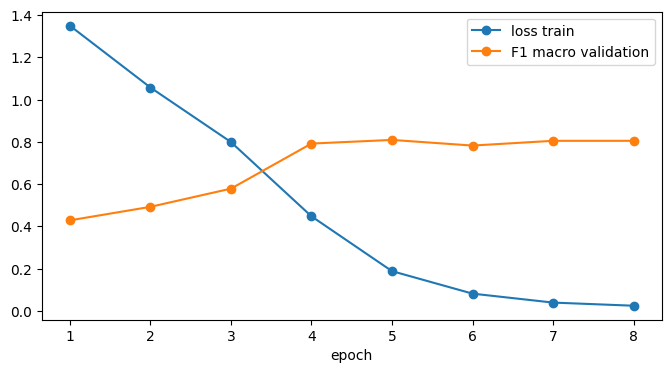

In [10]:
set_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT, num_labels=NUM_LABELS, id2label=ID2LABEL, label2id=LABEL2ID).to(DEVICE)


def val_score(model):
    probs = doc_probs(val_records, predict_probs(model, val_records, EVAL_BS)).loc[df_val["id"]]
    return scores(df_val["label_id"], probs.values.argmax(1))


if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
history, best_val_f1 = train_model(model, train_records, val_score)
train_time_s = time.perf_counter() - t0
peak_vram_train = vram_peak_gb()

print(f"\nEntraînement : {train_time_s / 60:.1f} min | VRAM max : {peak_vram_train} Go")
print(f"Meilleur F1 macro en validation : {best_val_f1:.4f} (epoch {history['f1_macro'].idxmax() + 1})")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history["epoch"], history["loss_train"], marker="o", label="loss train")
ax.plot(history["epoch"], history["f1_macro"], marker="o", label="F1 macro validation")
ax.set_xlabel("epoch")
ax.legend()
plt.show()

## 5.5 Évaluation sur le test

DrBERT chunking + fenêtres :
Coefficient de Kappa : 0.8080
Niveau d'accord (Landis & Koch) : Presque parfait

Rapport de classification
               precision    recall  f1-score   support

Ancien fumeur       0.86      0.75      0.80        16
Fumeur actuel       0.65      0.61      0.63        18
Non mentionné       0.95      0.98      0.97        61
   Non-fumeur       0.85      0.88      0.86        25

     accuracy                           0.88       120
    macro avg       0.83      0.81      0.81       120
 weighted avg       0.87      0.88      0.87       120



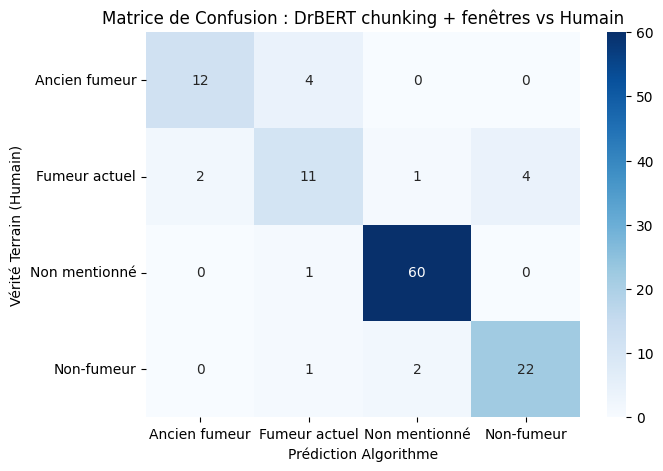




F1 macro : 0.8148 | Accuracy : 0.8750 | Précision : 0.8257 | Rappel : 0.8062
Inférence : 1.1 s | VRAM : 0.97 Go


In [11]:
if DEVICE == "cuda":
    torch.cuda.reset_peak_memory_stats()
t0 = time.perf_counter()
test_probs = doc_probs(test_records, predict_probs(model, test_records, EVAL_BS)).loc[df_test["id"]]
infer_time_s = time.perf_counter() - t0
peak_vram_infer = vram_peak_gb()

y_true = df_test["label_id"].values
y_pred = test_probs.values.argmax(1)
info_test = test_info.set_index("doc_id").loc[df_test["id"]]

pred_df = evaluate_and_save(
    "DrBERT chunking + fenêtres", df_test["id"].values, y_true, y_pred, test_probs.values,
    extra_cols={"seq_type": info_test["seq_type"], "n_doc_tokens": info_test["n_doc_tokens"],
                "n_seqs": info_test["n_seqs"]},
    infos={"train_time_s": round(train_time_s, 1), "inference_time_s": round(infer_time_s, 2),
           "inference_ms_per_doc": round(1000 * infer_time_s / len(df_test), 1),
           "preprocessing_test_s": round(prep_test_s, 2),
           "peak_vram_train_gb": peak_vram_train, "peak_vram_infer_gb": peak_vram_infer,
           "best_val_f1_macro": round(best_val_f1, 4), "aggregation": "mean",
           "n_test_sequences": len(test_records),
           "config": {"model": MODEL_CHECKPOINT, "max_len": MAX_LEN, "ctx_tokens": CTX_TOKENS, "epochs": EPOCHS,
                      "lr": LR, "train_bs": TRAIN_BS, "grad_acc": GRAD_ACC, "seed": SEED,
                      "test_size": TEST_SIZE, "val_size": VAL_SIZE}},
)
print(f"Inférence : {infer_time_s:.1f} s | VRAM : {peak_vram_infer} Go")

## 5.6 Biais de longueur

On vérifie que le modèle ne s'appuie pas sur la longueur des documents plutôt que sur leur contenu :
- performances par quartile de longueur et par type de séquence ;
- longueur des documents selon la classe dans le train ;
- ratio de padding pour les documents gardés en entier ;
- inférence avec un padding fixe à 512 : grâce à l'`attention_mask`, les prédictions ne devraient pas changer.

,n_docs,accuracy,f1_macro,% Non mentionné
len_bin,,,,
"(77.999, 327.0]",30.0,1.000,0.500,0.967
"(327.0, 532.5]",30.0,0.833,0.552,0.633
"(532.5, 805.5]",30.0,0.900,0.892,0.333
"(805.5, 3689.0]",30.0,0.767,0.807,0.100


,n_docs,accuracy,f1_macro,% Non mentionné
seq_type,,,,
chunk,14.0,1.000,0.250,1.000
full,53.0,0.925,0.536,0.849
window,53.0,0.792,0.713,0.038


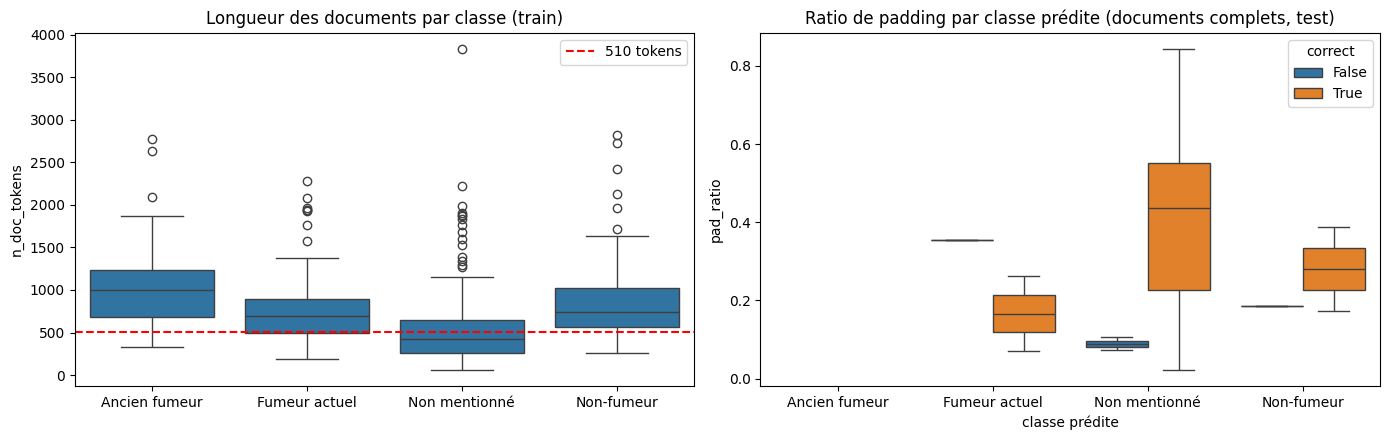

,count,mean,median
correct,,,
False,4,0.180,0.146
True,49,0.401,0.408


Prédictions identiques : 100.0% | écart max de probabilité : 0.0000


In [12]:
an = pred_df.copy()
an["correct"] = an["y_true_id"] == an["y_pred_id"]
an["len_bin"] = pd.qcut(an["n_doc_tokens"], q=4, duplicates="drop")


def group_perf(g):
    return pd.Series({"n_docs": len(g), "accuracy": g["correct"].mean(),
                      "f1_macro": f1_score(g["y_true_id"], g["y_pred_id"], average="macro",
                                           labels=range(NUM_LABELS), zero_division=0),
                      "% Non mentionné": (g["y_true"] == "Non mentionné").mean()})


cols = ["correct", "y_true_id", "y_pred_id", "y_true"]
display(an.groupby("len_bin", observed=True)[cols].apply(group_perf).round(3))
display(an.groupby("seq_type")[cols].apply(group_perf).round(3))

tr = train_info.assign(label=train_info["label_id"].map(ID2LABEL))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=tr, x="label", y="n_doc_tokens", order=CLASSES, ax=axes[0])
axes[0].axhline(BODY_LEN, color="red", ls="--", label=f"{BODY_LEN} tokens")
axes[0].legend()
axes[0].set_title("Longueur des documents par classe (train)")
axes[0].set_xlabel("")

full = an[an["seq_type"] == "full"].copy()
full["pad_ratio"] = 1 - (full["n_doc_tokens"] + 2) / MAX_LEN
sns.boxplot(data=full, x="y_pred", y="pad_ratio", hue="correct", order=CLASSES, ax=axes[1])
axes[1].set_title("Ratio de padding par classe prédite (documents complets, test)")
axes[1].set_xlabel("classe prédite")
plt.tight_layout()
plt.show()

display(full.groupby("correct")["pad_ratio"].agg(["count", "mean", "median"]).round(3))

# même inférence avec un padding fixe à 512
probs_fixed = doc_probs(test_records, predict_probs(model, test_records, EVAL_BS, pad_to=MAX_LEN)).loc[df_test["id"]]
same_pred = (probs_fixed.values.argmax(1) == y_pred).mean()
max_diff = np.abs(probs_fixed.values - test_probs.values).max()
print(f"Prédictions identiques : {same_pred:.1%} | écart max de probabilité : {max_diff:.4f}")

Le padding est masqué par l'attention, le dernier test doit donc donner les mêmes prédictions. Ce qui compte plus, c'est le lien entre longueur et classe : les longs documents sans mention sont presque tous « Non mentionné », donc bien les classer n'est pas forcément un raccourci du modèle. Les cas intéressants sont les documents découpés en chunks dont la vraie classe est une classe tabac (mentions ratées par la regex).